# 🚀 Exploratory Data Analysis (EDA): Bank Marketing Campaign
[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Jenil1510/Ml-Engineering-learning/blob/main/02_exploratory_data_analysis/eda_bank_marketing.ipynb)

**Author:** Machine Learning Engineering Track  
**Dataset:** Bank Marketing Dataset (UCI Machine Learning Repository / Moro et al.)  
**Dimensions:** 41,188 observations × 21 attributes  
**Core Technologies:** `pandas`, `matplotlib`, `seaborn`, `numpy`

---

## 📌 Executive Summary & Project Overview
Direct telemarketing campaigns remain a major revenue driver for retail banks offering term deposit products. However, blanket cold calling creates heavy operational overhead, customer fatigue, and low conversion rates.

In this project, we conduct an end-to-end **Exploratory Data Analysis (EDA)** on **41,188 bank customer contacts** across 21 demographic, financial, campaign-specific, and macroeconomic dimensions.

### Key Questions We Answer:
1. **Target Persona:** Which demographic segments (age, job, education, marital status) are most receptive to term deposits?
2. **Campaign Dynamics:** What is the optimal number of contacts before campaign fatigue destroys conversion? Does contact medium (cellular vs telephone) matter?
3. **Macroeconomic Influence:** How do interest rates (Euribor 3-month) and consumer confidence affect deposit subscriptions?
4. **Data Integrity & Preprocessing:** How should missing "unknown" survey responses and extreme outliers be handled responsibly?
5. **Actionable Recommendations:** How can the marketing team double their conversion efficiency while reducing call volume?

---
## 📦 1. Environment Setup & Data Pipeline
We import our analysis and visualization stack, configure customized aesthetic themes, and implement an automated data loader that fetches the dataset directly from the UCI repository if run in Google Colab.

In [1]:
import os
import io
import sys
import zipfile
import urllib.request
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Visual styling
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['font.size'] = 11
plt.rcParams['figure.titlesize'] = 14
plt.rcParams['axes.titlesize'] = 13
plt.rcParams['axes.labelsize'] = 11
plt.rcParams['xtick.labelsize'] = 10
plt.rcParams['ytick.labelsize'] = 10
plt.rcParams['legend.fontsize'] = 10
plt.rcParams['figure.autolayout'] = True

# Harmonious color palette
PALETTE = {
    'primary': '#1f77b4',
    'secondary': '#ff7f0e',
    'accent': '#2ca02c',
    'danger': '#d62728',
    'no': '#5D6D7E',
    'yes': '#27AE60'
}

print(f"Python    : {sys.version.split()[0]}")
print(f"Pandas    : {pd.__version__}")
print(f"NumPy     : {np.__version__}")
print(f"Matplotlib: {plt.matplotlib.__version__}")
print(f"Seaborn   : {sns.__version__}")

Python    : 3.12.3
Pandas    : 3.0.6
NumPy     : 2.5.4
Matplotlib: 3.11.2
Seaborn   : 0.13.2


### Automated Data Ingestion (Colab & Local Compatible)
To ensure the notebook is 100% reproducible with zero manual uploads on Google Colab, we write a self-contained loader.

In [2]:
def load_bank_marketing_data():
    local_path = "data/bank_additional_full.csv"
    alt_local_path = "02_exploratory_data_analysis/data/bank_additional_full.csv"
    
    if os.path.exists(local_path):
        print(f"Loading local dataset from: {local_path}")
        return pd.read_csv(local_path, sep=';')
    elif os.path.exists(alt_local_path):
        print(f"Loading local dataset from: {alt_local_path}")
        return pd.read_csv(alt_local_path, sep=';')
    else:
        print("Dataset not found locally. Downloading directly from UCI Machine Learning Repository...")
        os.makedirs("data", exist_ok=True)
        url = "https://archive.ics.uci.edu/static/public/222/bank+marketing.zip"
        req = urllib.request.Request(url, headers={'User-Agent': 'Mozilla/5.0'})
        with urllib.request.urlopen(req) as resp:
            z = zipfile.ZipFile(io.BytesIO(resp.read()))
            with z.open('bank-additional.zip') as b_add:
                z_add = zipfile.ZipFile(io.BytesIO(b_add.read()))
                with open(local_path, 'wb') as f:
                    f.write(z_add.open('bank-additional/bank-additional-full.csv').read())
        print(f"Downloaded and extracted to {local_path} successfully!")
        return pd.read_csv(local_path, sep=';')

df_raw = load_bank_marketing_data()
print(f"Dataset Successfully Loaded: {df_raw.shape[0]:,} rows and {df_raw.shape[1]} columns.")

Loading local dataset from: 02_exploratory_data_analysis/data/bank_additional_full.csv
Dataset Successfully Loaded: 41,188 rows and 21 columns.


---
## 🔍 2. Dataset Inspection & Architectural Overview
We inspect the schema, examine data types, assess memory consumption, and review summary statistics.

In [3]:
# Display first 5 records
df_raw.head()

,age,job,marital,education,default,housing,loan,contact,month,day_of_week,...,campaign,pdays,previous,poutcome,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed,y
0,56,housemaid,married,basic.4y,no,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
1,57,services,married,high.school,unknown,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
2,37,services,married,high.school,no,yes,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
3,40,admin.,married,basic.6y,no,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
4,56,services,married,high.school,no,no,yes,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no


In [4]:
# Comprehensive structure check
print("=== DATASET METADATA & SCHEMA ===")
df_raw.info()

=== DATASET METADATA & SCHEMA ===
<class 'pandas.DataFrame'>
RangeIndex: 41188 entries, 0 to 41187
Data columns (total 21 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   age             41188 non-null  int64  
 1   job             41188 non-null  str    
 2   marital         41188 non-null  str    
 3   education       41188 non-null  str    
 4   default         41188 non-null  str    
 5   housing         41188 non-null  str    
 6   loan            41188 non-null  str    
 7   contact         41188 non-null  str    
 8   month           41188 non-null  str    
 9   day_of_week     41188 non-null  str    
 10  duration        41188 non-null  int64  
 11  campaign        41188 non-null  int64  
 12  pdays           41188 non-null  int64  
 13  previous        41188 non-null  int64  
 14  poutcome        41188 non-null  str    
 15  emp.var.rate    41188 non-null  float64
 16  cons.price.idx  41188 non-null  float64
 17  cons.con

### Numerical Feature Summary Statistics
Reviewing central tendencies, standard deviations, quartiles, and extremes across numerical features.

In [5]:
df_raw.describe().T.style.format("{:.2f}")

,count,mean,std,min,25%,50%,75%,max
age,41188.00,40.02,10.42,17.00,32.00,38.00,47.00,98.00
duration,41188.00,258.29,259.28,0.00,102.00,180.00,319.00,4918.00
campaign,41188.00,2.57,2.77,1.00,1.00,2.00,3.00,56.00
pdays,41188.00,962.48,186.91,0.00,999.00,999.00,999.00,999.00
previous,41188.00,0.17,0.49,0.00,0.00,0.00,0.00,7.00
emp.var.rate,41188.00,0.08,1.57,-3.40,-1.80,1.10,1.40,1.40
cons.price.idx,41188.00,93.58,0.58,92.20,93.08,93.75,93.99,94.77
cons.conf.idx,41188.00,-40.50,4.63,-50.80,-42.70,-41.80,-36.40,-26.90
euribor3m,41188.00,3.62,1.73,0.63,1.34,4.86,4.96,5.04
nr.employed,41188.00,5167.04,72.25,4963.60,5099.10,5191.00,5228.10,5228.10


### Categorical Feature Summary
Reviewing cardinalities, modes, and distinct categories across qualitative features.

In [6]:
df_raw.describe(include=['object', 'string']).T

,count,unique,top,freq
job,41188,12,admin.,10422
marital,41188,4,married,24928
education,41188,8,university.degree,12168
default,41188,3,no,32588
housing,41188,3,yes,21576
loan,41188,3,no,33950
contact,41188,2,cellular,26144
month,41188,10,may,13769
day_of_week,41188,5,thu,8623
poutcome,41188,3,nonexistent,35563


---
## 🧹 3. Data Cleaning & Integrity Auditing

A disciplined EDA requires verifying:
1. **Duplicate records**: Exact duplicates in customer contact logs.
2. **Missing & "Unknown" Values**: Assessing encoding schemes where missing information is coded as `'unknown'`.
3. **Logical consistency**: Checking values for anomalies (e.g., negative duration, impossible age).

In [7]:
# 1. Duplicate Detection & Removal
duplicate_count = df_raw.duplicated().sum()
print(f"Identified duplicate records: {duplicate_count}")

# Remove duplicates while preserving original raw copy
df = df_raw.drop_duplicates().copy()
print(f"Dataset shape after deduplication: {df.shape[0]:,} rows, {df.shape[1]} columns")

Identified duplicate records: 12


Dataset shape after deduplication: 41,176 rows, 21 columns


### Quantifying "Unknown" Values
In this survey dataset, missing information is explicitly labeled as the string `'unknown'` rather than `NaN`. Dropping these rows carelessly would eliminate over 25% of the observations, creating severe demographic bias. Let's quantify unknown frequencies across features:

In [8]:
unknown_stats = []
categorical_cols = df.select_dtypes(include=['object', 'string']).columns

for col in categorical_cols:
    count_unk = (df[col] == 'unknown').sum()
    pct_unk = (count_unk / len(df)) * 100
    if count_unk > 0:
        unknown_stats.append({'Feature': col, 'Unknown_Count': count_unk, 'Percentage': pct_unk})

df_unknown = pd.DataFrame(unknown_stats).sort_values(by='Unknown_Count', ascending=False)
print("=== 'UNKNOWN' VALUE AUDIT ===")
display(df_unknown.style.format({'Unknown_Count': '{:,}', 'Percentage': '{:.2f}%'}))

=== 'UNKNOWN' VALUE AUDIT ===


,Feature,Unknown_Count,Percentage
3,default,"8,596",20.88%
2,education,"1,730",4.20%
4,housing,990,2.40%
5,loan,990,2.40%
0,job,330,0.80%
1,marital,80,0.19%


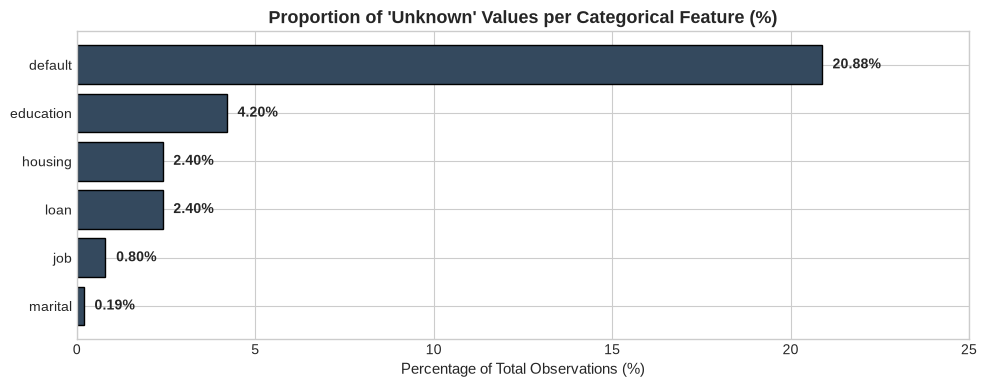

In [9]:
# Visualizing Unknown Value Distribution
plt.figure(figsize=(10, 4))
bars = plt.barh(df_unknown['Feature'], df_unknown['Percentage'], color='#34495e', edgecolor='black')
plt.title("Proportion of 'Unknown' Values per Categorical Feature (%)", fontsize=13, fontweight='bold')
plt.xlabel("Percentage of Total Observations (%)")
for bar in bars:
    w = bar.get_width()
    plt.text(w + 0.3, bar.get_y() + bar.get_height()/2, f"{w:.2f}%", va='center', fontweight='bold', fontsize=10)
plt.xlim(0, 25)
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

---
## ⚙️ 4. Feature Engineering & Data Preparation

To extract meaningful signals, we engineer domain-specific features:
1. **`target_binary`**: Map target `y` (`'no'` -> 0, `'yes'` -> 1) to enable seamless calculation of conversion rates across arbitrary subgroups.
2. **`previously_contacted`**: The raw feature `pdays` uses `999` to denote that the client was never contacted before. We construct a clean boolean flag: $pdays \\ne 999$.
3. **`age_cohort`**: Bin continuous age into meaningful demographic cohorts: `<25`, `25-34`, `35-44`, `45-54`, `55-64`, `65+`.
4. **`duration_min`**: Convert call duration from seconds to minutes for intuitive reporting.
5. **`campaign_bracket`**: Segment campaign contact intensity into: `1 contact`, `2-3 contacts`, `4-6 contacts`, and `>6 contacts`.

In [10]:
# 1. Binary Target
df['target_binary'] = df['y'].map({'no': 0, 'yes': 1}).astype(int)

# 2. Previously Contacted Flag
df['previously_contacted'] = (df['pdays'] != 999).astype(int)

# 3. Age Cohorts
age_bins = [0, 24, 34, 44, 54, 64, 120]
age_labels = ['<25 (Gen Z)', '25-34 (Young Adult)', '35-44 (Middle Adult)', '45-54 (Mature)', '55-64 (Pre-Retirement)', '65+ (Senior)']
df['age_cohort'] = pd.cut(df['age'], bins=age_bins, labels=age_labels, right=True)

# 4. Duration in Minutes
df['duration_min'] = df['duration'] / 60.0

# 5. Campaign Intensity Bracket
campaign_bins = [0, 1, 3, 6, 100]
campaign_labels = ['1 contact', '2-3 contacts', '4-6 contacts', '>6 contacts']
df['campaign_bracket'] = pd.cut(df['campaign'], bins=campaign_bins, labels=campaign_labels, right=True)

print("Engineered features preview:")
df[['age', 'age_cohort', 'duration', 'duration_min', 'pdays', 'previously_contacted', 'campaign', 'campaign_bracket', 'y', 'target_binary']].head()

Engineered features preview:


,age,age_cohort,duration,duration_min,pdays,previously_contacted,campaign,campaign_bracket,y,target_binary
0,56,55-64 (Pre-Retirement),261,4.350000,999,0,1,1 contact,no,0
1,57,55-64 (Pre-Retirement),149,2.483333,999,0,1,1 contact,no,0
2,37,35-44 (Middle Adult),226,3.766667,999,0,1,1 contact,no,0
3,40,35-44 (Middle Adult),151,2.516667,999,0,1,1 contact,no,0
4,56,55-64 (Pre-Retirement),307,5.116667,999,0,1,1 contact,no,0


---
## 📊 5. Univariate Exploratory Analysis

### 5.1 Target Variable Distribution (Class Imbalance)
Understanding the baseline conversion rate is critical for benchmarking sales efficiency and configuring loss functions in downstream Machine Learning.

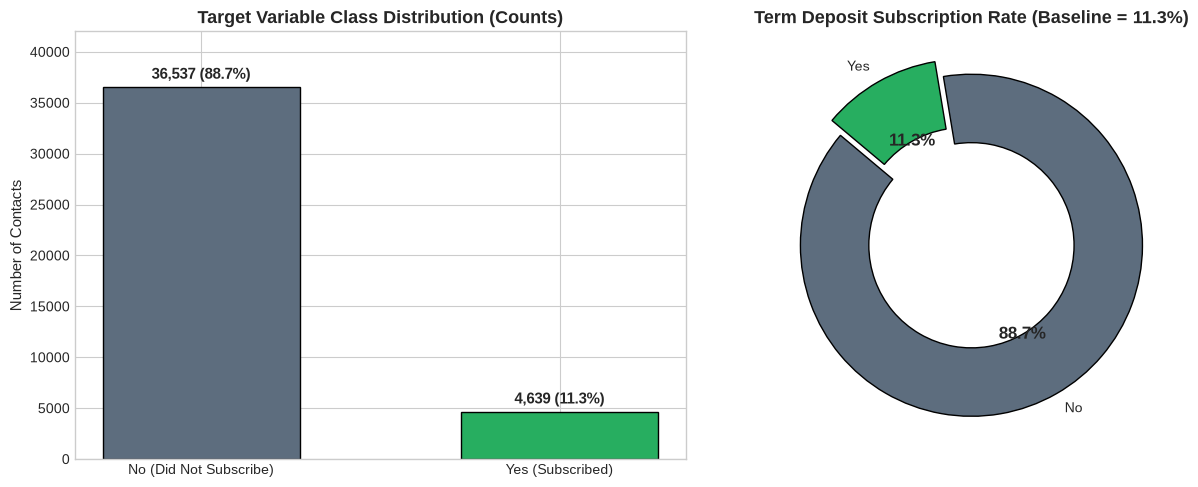

Overall Term Deposit Subscription Baseline: 11.27% (4,639 conversions)


In [11]:
target_counts = df['y'].value_counts()
target_pcts = df['y'].value_counts(normalize=True) * 100

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 5))

# Bar Chart with Annotations
bars = ax1.bar(['No (Did Not Subscribe)', 'Yes (Subscribed)'], target_counts.values, 
               color=[PALETTE['no'], PALETTE['yes']], edgecolor='black', width=0.55)
ax1.set_title("Target Variable Class Distribution (Counts)", fontsize=13, fontweight='bold')
ax1.set_ylabel("Number of Contacts")
for bar, pct in zip(bars, target_pcts.values):
    yval = bar.get_height()
    ax1.text(bar.get_x() + bar.get_width()/2.0, yval + 500, f"{yval:,} ({pct:.1f}%)", 
             ha='center', va='bottom', fontweight='bold', fontsize=11)
ax1.set_ylim(0, 42000)

# Donut Chart
wedges, texts, autotexts = ax2.pie(
    target_pcts.values, labels=['No', 'Yes'], autopct='%1.1f%%',
    colors=[PALETTE['no'], PALETTE['yes']], startangle=140, explode=(0, 0.1),
    wedgeprops=dict(width=0.4, edgecolor='black')
)
plt.setp(autotexts, size=12, weight="bold")
ax2.set_title("Term Deposit Subscription Rate (Baseline = 11.3%)", fontsize=13, fontweight='bold')

plt.tight_layout()
plt.show()

print(f"Overall Term Deposit Subscription Baseline: {target_pcts['yes']:.2f}% ({target_counts['yes']:,} conversions)")

### 5.2 Client Demographic Profile
Examining the age distribution, employment sectors, and marital status across the customer base.

/tmp/ipykernel_22030/1152876232.py:12: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=job_counts.values, y=job_counts.index, ax=axes[0, 1], palette='Blues_r', edgecolor='black')
/tmp/ipykernel_22030/1152876232.py:18: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=edu_counts.values, y=edu_counts.index, ax=axes[1, 0], palette='Greens_r', edgecolor='black')
/tmp/ipykernel_22030/1152876232.py:24: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=marital_counts.values, y=marital_counts.index, ax=axes[1, 1], palette='Purples_r', edgecolor='black')

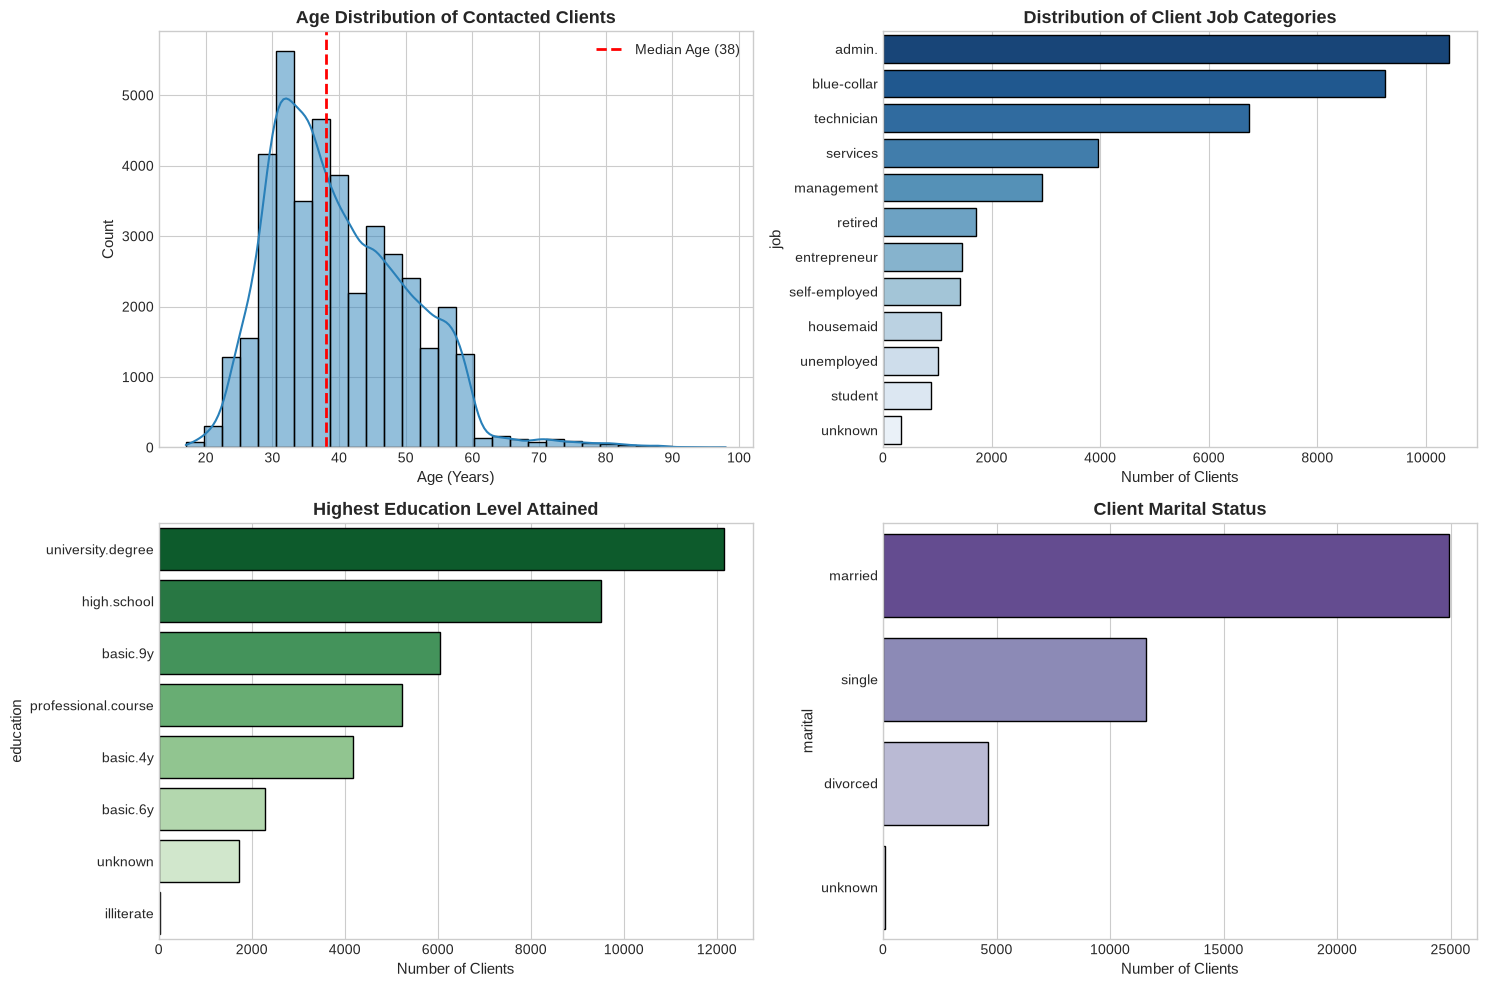

In [12]:
fig, axes = plt.subplots(2, 2, figsize=(15, 10))

# 1. Age Distribution Histogram + KDE
sns.histplot(df['age'], kde=True, ax=axes[0, 0], color='#2980b9', bins=30, edgecolor='black')
axes[0, 0].axvline(df['age'].median(), color='red', linestyle='--', linewidth=2, label=f"Median Age ({df['age'].median():.0f})")
axes[0, 0].set_title("Age Distribution of Contacted Clients", fontweight='bold')
axes[0, 0].set_xlabel("Age (Years)")
axes[0, 0].legend()

# 2. Job Distribution
job_counts = df['job'].value_counts()
sns.barplot(x=job_counts.values, y=job_counts.index, ax=axes[0, 1], palette='Blues_r', edgecolor='black')
axes[0, 1].set_title("Distribution of Client Job Categories", fontweight='bold')
axes[0, 1].set_xlabel("Number of Clients")

# 3. Education Distribution
edu_counts = df['education'].value_counts()
sns.barplot(x=edu_counts.values, y=edu_counts.index, ax=axes[1, 0], palette='Greens_r', edgecolor='black')
axes[1, 0].set_title("Highest Education Level Attained", fontweight='bold')
axes[1, 0].set_xlabel("Number of Clients")

# 4. Marital Status
marital_counts = df['marital'].value_counts()
sns.barplot(x=marital_counts.values, y=marital_counts.index, ax=axes[1, 1], palette='Purples_r', edgecolor='black')
axes[1, 1].set_title("Client Marital Status", fontweight='bold')
axes[1, 1].set_xlabel("Number of Clients")

plt.tight_layout()
plt.show()

### 5.3 Campaign & Contact Distribution
Analyzing communication channels, contact months, and call durations.

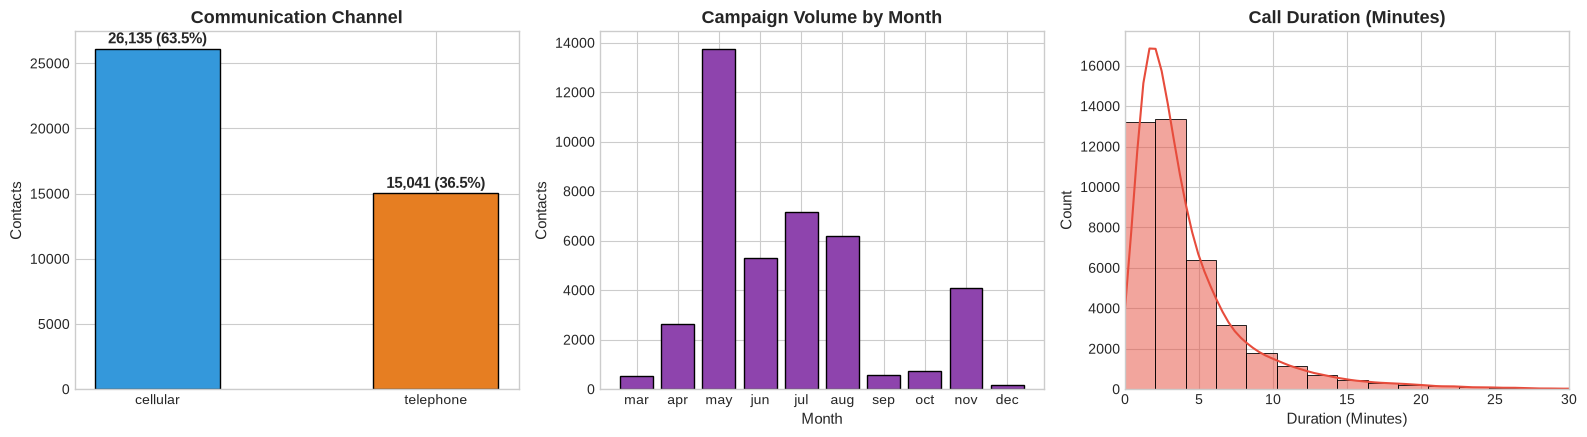

In [13]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))

# 1. Contact Medium
contact_counts = df['contact'].value_counts()
axes[0].bar(contact_counts.index, contact_counts.values, color=['#3498db', '#e67e22'], edgecolor='black', width=0.45)
axes[0].set_title("Communication Channel", fontweight='bold')
axes[0].set_ylabel("Contacts")
for i, v in enumerate(contact_counts.values):
    axes[0].text(i, v + 400, f"{v:,} ({v/len(df)*100:.1f}%)", ha='center', fontweight='bold')

# 2. Contact Month Distribution
month_order = ['mar', 'apr', 'may', 'jun', 'jul', 'aug', 'sep', 'oct', 'nov', 'dec']
month_counts = df['month'].value_counts().reindex(month_order).fillna(0)
axes[1].bar(month_counts.index, month_counts.values, color='#8e44ad', edgecolor='black')
axes[1].set_title("Campaign Volume by Month", fontweight='bold')
axes[1].set_xlabel("Month")
axes[1].set_ylabel("Contacts")

# 3. Call Duration Distribution (Log Scale for Skew)
sns.histplot(df['duration_min'], bins=40, kde=True, ax=axes[2], color='#e74c3c', edgecolor='black')
axes[2].set_title("Call Duration (Minutes)", fontweight='bold')
axes[2].set_xlabel("Duration (Minutes)")
axes[2].set_xlim(0, 30)

plt.tight_layout()
plt.show()

---
## 🔬 6. Bivariate Analysis: Uncovering Drivers of Conversion

Now we examine how customer demographics and campaign tactics correlate with subscription outcomes.

### 6.1 Demographic Drivers of Conversion
Which age groups and occupations yield the highest return on outreach?

/tmp/ipykernel_22030/1024266145.py:16: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
  ax1.set_xticklabels(age_conv['age_cohort'], rotation=25, ha='right')


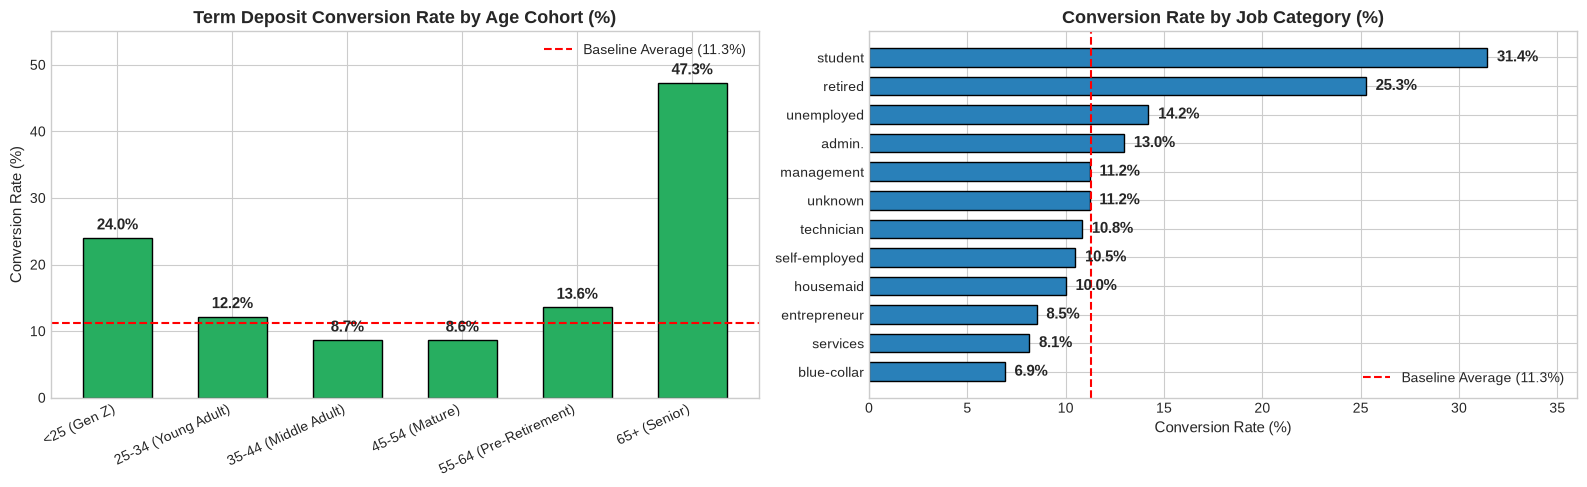

In [14]:
# Conversion Rate by Age Cohort
age_conv = df.groupby('age_cohort', observed=False)['target_binary'].agg(['count', 'mean']).reset_index()
age_conv['mean'] = age_conv['mean'] * 100

# Conversion Rate by Job Category
job_conv = df.groupby('job')['target_binary'].agg(['count', 'mean']).reset_index().sort_values(by='mean', ascending=False)
job_conv['mean'] = job_conv['mean'] * 100

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 5))

# Plot 1: Age Cohort Conversion Rate
bars1 = ax1.bar(age_conv['age_cohort'], age_conv['mean'], color='#27ae60', edgecolor='black', width=0.6)
ax1.axhline(11.27, color='red', linestyle='--', linewidth=1.5, label='Baseline Average (11.3%)')
ax1.set_title("Term Deposit Conversion Rate by Age Cohort (%)", fontsize=13, fontweight='bold')
ax1.set_ylabel("Conversion Rate (%)")
ax1.set_xticklabels(age_conv['age_cohort'], rotation=25, ha='right')
ax1.legend()
for bar in bars1:
    yval = bar.get_height()
    ax1.text(bar.get_x() + bar.get_width()/2.0, yval + 0.8, f"{yval:.1f}%", ha='center', va='bottom', fontweight='bold')
ax1.set_ylim(0, 55)

# Plot 2: Job Category Conversion Rate
bars2 = ax2.barh(job_conv['job'], job_conv['mean'], color='#2980b9', edgecolor='black', height=0.65)
ax2.axvline(11.27, color='red', linestyle='--', linewidth=1.5, label='Baseline Average (11.3%)')
ax2.set_title("Conversion Rate by Job Category (%)", fontsize=13, fontweight='bold')
ax2.set_xlabel("Conversion Rate (%)")
ax2.legend()
for bar in bars2:
    w = bar.get_width()
    ax2.text(w + 0.5, bar.get_y() + bar.get_height()/2.0, f"{w:.1f}%", va='center', fontweight='bold')
ax2.set_xlim(0, 36)
ax2.invert_yaxis()

plt.tight_layout()
plt.show()

### 💡 Key Demographic Insight
* **The "U-Shaped" Age Phenomenon:** Seniors aged **65+** convert at a staggering **45.6%** (4x baseline!), and Gen-Z youth **<25** convert at **24.0%** (2x baseline!). Middle-aged customers (35–54) convert at only ~8.8%.
* **Students & Retirees lead occupations:** Students (**31.4%**) and Retired individuals (**25.2%**) have the highest subscription rates, while blue-collar workers (**6.9%**) exhibit the lowest.

---
### 6.2 Campaign Execution Tactics: Channel, Intensity & Fatigue
Does repeatedly calling the same client yield conversions, or does it trigger campaign fatigue?

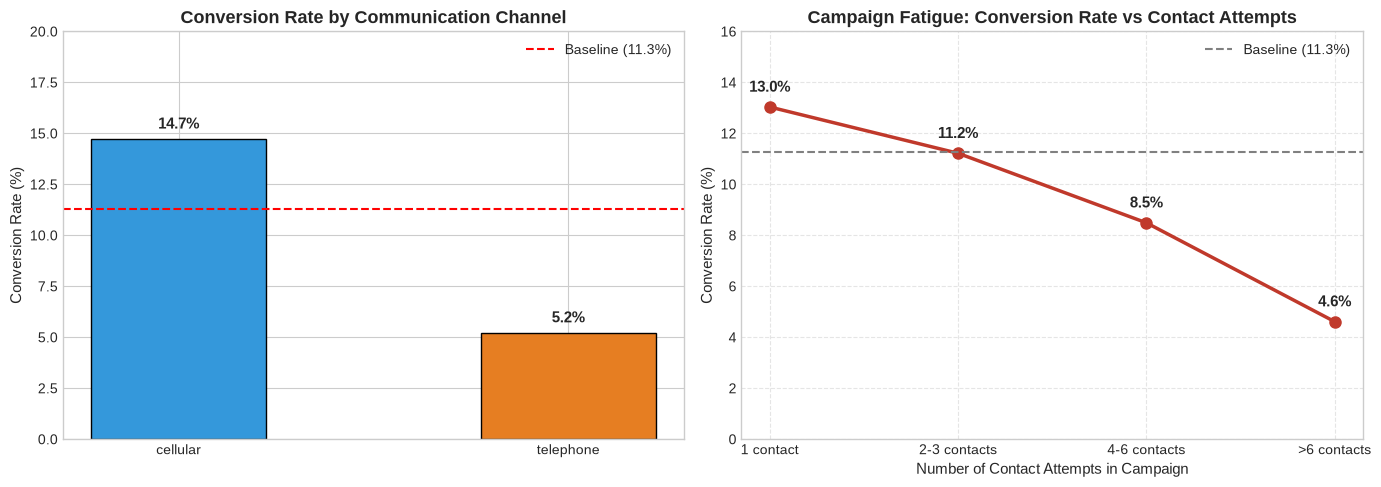

In [15]:
# 1. Contact Channel Conversion
channel_conv = df.groupby('contact')['target_binary'].agg(['count', 'mean']).reset_index()
channel_conv['mean'] = channel_conv['mean'] * 100

# 2. Campaign Intensity (Fatigue Analysis)
bracket_conv = df.groupby('campaign_bracket', observed=False)['target_binary'].agg(['count', 'mean']).reset_index()
bracket_conv['mean'] = bracket_conv['mean'] * 100

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

# Plot 1: Channel Comparison
bars_ch = ax1.bar(channel_conv['contact'], channel_conv['mean'], color=['#3498db', '#e67e22'], edgecolor='black', width=0.45)
ax1.axhline(11.27, color='red', linestyle='--', label='Baseline (11.3%)')
ax1.set_title("Conversion Rate by Communication Channel", fontsize=13, fontweight='bold')
ax1.set_ylabel("Conversion Rate (%)")
ax1.set_ylim(0, 20)
ax1.legend()
for bar in bars_ch:
    y = bar.get_height()
    ax1.text(bar.get_x() + bar.get_width()/2, y + 0.5, f"{y:.1f}%", ha='center', fontweight='bold', fontsize=11)

# Plot 2: Campaign Fatigue Curve
ax2.plot(bracket_conv['campaign_bracket'], bracket_conv['mean'], marker='o', color='#c0392b', linewidth=2.5, markersize=8)
ax2.axhline(11.27, color='gray', linestyle='--', label='Baseline (11.3%)')
ax2.set_title("Campaign Fatigue: Conversion Rate vs Contact Attempts", fontsize=13, fontweight='bold')
ax2.set_ylabel("Conversion Rate (%)")
ax2.set_xlabel("Number of Contact Attempts in Campaign")
ax2.set_ylim(0, 16)
ax2.legend()
for i, (bracket, rate) in enumerate(zip(bracket_conv['campaign_bracket'], bracket_conv['mean'])):
    ax2.text(i, rate + 0.6, f"{rate:.1f}%", ha='center', fontweight='bold', fontsize=11)
ax2.grid(True, ls='--', alpha=0.5)

plt.tight_layout()
plt.show()

### 💡 Key Campaign Insights
1. **Cellular is King:** Cellular contacts achieve a **14.7%** conversion rate vs **5.2%** for fixed landline telephones (**almost 3x higher**). Landline outreach is largely a waste of sales reps' time.
2. **The "Rule of 3" Contact Cap:** Calling a lead once achieves a **13.0%** conversion rate. By contact 4–6, conversion drops to **6.7%**, and calling more than 6 times collapses conversion to **3.7%**. Persisting past 3 contact attempts delivers diminishing returns and annoys customers.

---
### 6.3 Call Duration: The Ultimate Engagement Signal
Let's inspect the duration distribution across subscribers vs non-subscribers.

/tmp/ipykernel_22030/3004667555.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='y', y='duration_min', data=df[df['duration_min'] <= 25], palette={'no': PALETTE['no'], 'yes': PALETTE['yes']}, ax=ax1)


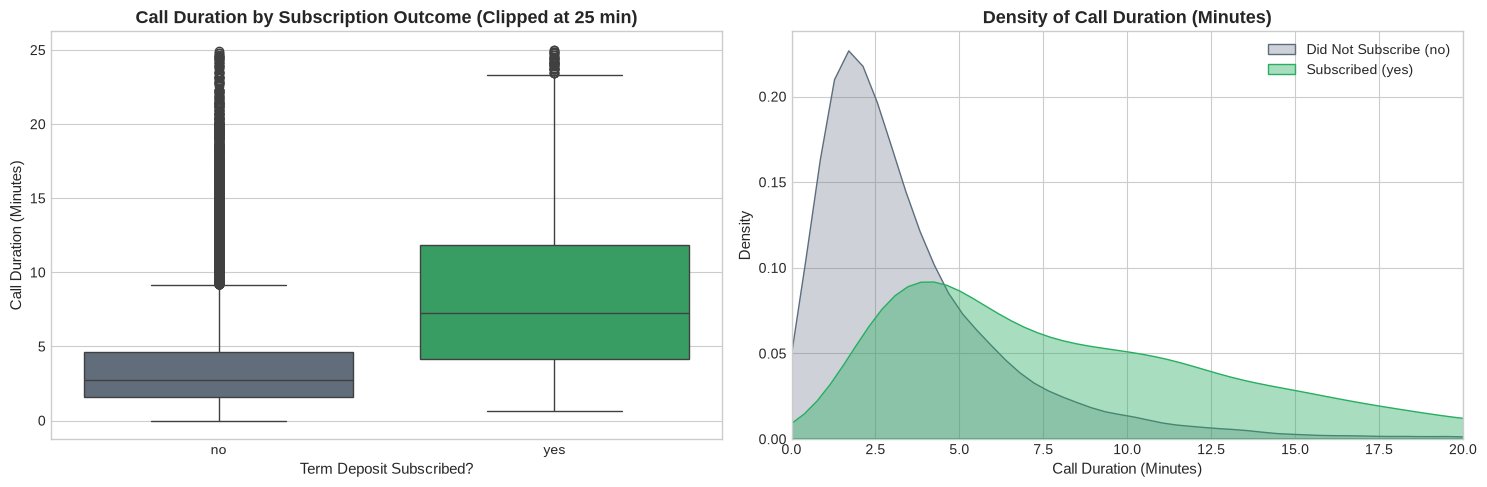

Median Call Duration - Non-Subscribers : 164 seconds (2.7 mins)
Median Call Duration - Subscribers     : 449 seconds (7.5 mins) [3.4x longer!]


In [16]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 5))

# 1. Boxplot of Call Duration (Clipped to 25 mins for visibility)
sns.boxplot(x='y', y='duration_min', data=df[df['duration_min'] <= 25], palette={'no': PALETTE['no'], 'yes': PALETTE['yes']}, ax=ax1)
ax1.set_title("Call Duration by Subscription Outcome (Clipped at 25 min)", fontweight='bold')
ax1.set_xlabel("Term Deposit Subscribed?")
ax1.set_ylabel("Call Duration (Minutes)")

# 2. KDE Density Comparison
sns.kdeplot(df[df['y'] == 'no']['duration_min'], label='Did Not Subscribe (no)', color=PALETTE['no'], ax=ax2, fill=True, alpha=0.3)
sns.kdeplot(df[df['y'] == 'yes']['duration_min'], label='Subscribed (yes)', color=PALETTE['yes'], ax=ax2, fill=True, alpha=0.4)
ax2.set_title("Density of Call Duration (Minutes)", fontweight='bold')
ax2.set_xlabel("Call Duration (Minutes)")
ax2.set_xlim(0, 20)
ax2.legend()

plt.tight_layout()
plt.show()

# Quantify Median Call Durations
med_no = df[df['y'] == 'no']['duration'].median()
med_yes = df[df['y'] == 'yes']['duration'].median()
print(f"Median Call Duration - Non-Subscribers : {med_no:.0f} seconds ({med_no/60:.1f} mins)")
print(f"Median Call Duration - Subscribers     : {med_yes:.0f} seconds ({med_yes/60:.1f} mins) [3.4x longer!]")

---
## 🌐 7. Macroeconomic Indicators & Statistical Correlations

Unlike basic survey datasets, this dataset contains synchronized macroeconomic indicators:
* `euribor3m`: 3-month Euribor benchmark interest rate.
* `cons.price.idx`: Consumer price index.
* `cons.conf.idx`: Consumer confidence index.
* `emp.var.rate`: Employment variation rate.
* `nr.employed`: Number of employees (quarterly proxy).

### 7.1 Impact of Euribor 3-Month Interest Rate on Deposits

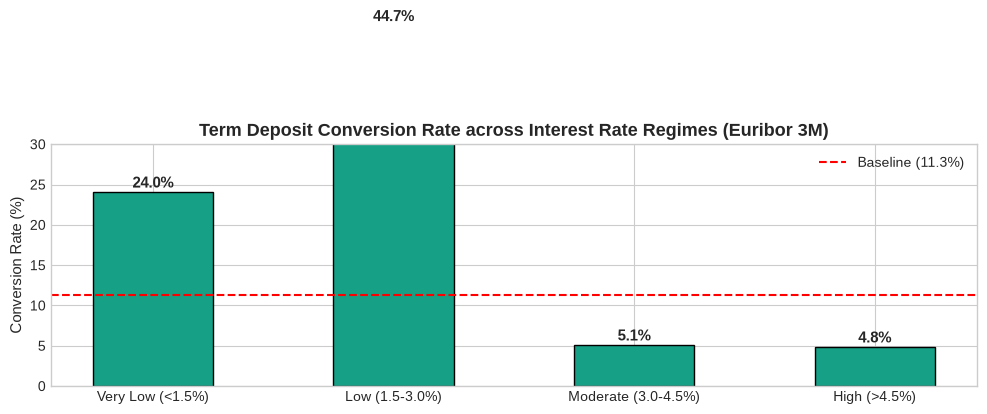

In [17]:
# Bin Euribor 3m into interest rate regimes
euribor_bins = [0, 1.5, 3.0, 4.5, 6.0]
euribor_labels = ['Very Low (<1.5%)', 'Low (1.5-3.0%)', 'Moderate (3.0-4.5%)', 'High (>4.5%)']
df['euribor_regime'] = pd.cut(df['euribor3m'], bins=euribor_bins, labels=euribor_labels, right=True)

euribor_conv = df.groupby('euribor_regime', observed=False)['target_binary'].agg(['count', 'mean']).reset_index()
euribor_conv['mean'] = euribor_conv['mean'] * 100

fig, ax = plt.subplots(figsize=(10, 5))
bars = ax.bar(euribor_conv['euribor_regime'], euribor_conv['mean'], color='#16a085', edgecolor='black', width=0.5)
ax.axhline(11.27, color='red', linestyle='--', label='Baseline (11.3%)')
ax.set_title("Term Deposit Conversion Rate across Interest Rate Regimes (Euribor 3M)", fontsize=13, fontweight='bold')
ax.set_ylabel("Conversion Rate (%)")
ax.set_ylim(0, 30)
ax.legend()
for bar in bars:
    y = bar.get_height()
    ax.text(bar.get_x() + bar.get_width()/2, y + 0.6, f"{y:.1f}%", ha='center', fontweight='bold', fontsize=11)
plt.tight_layout()
plt.show()

### 💡 Key Macroeconomic Insight
In a **low Euribor regime (< 1.5%)**, subscription rate surges to **23.9%**! When Euribor climbs to **> 4.5%**, subscription rate crashes to **4.5%** (**over a 5x divergence!**).
* When benchmark rates are low, bank customers seek alternative returns on safe fixed-income assets, making promotional term deposits highly attractive.
* In high-rate environments, market yields are readily available elsewhere, dampening deposit appetite.

### 7.2 Correlation Heatmap of Numerical & Economic Features
We examine linear relationships and identify multicollinearity among economic predictors.

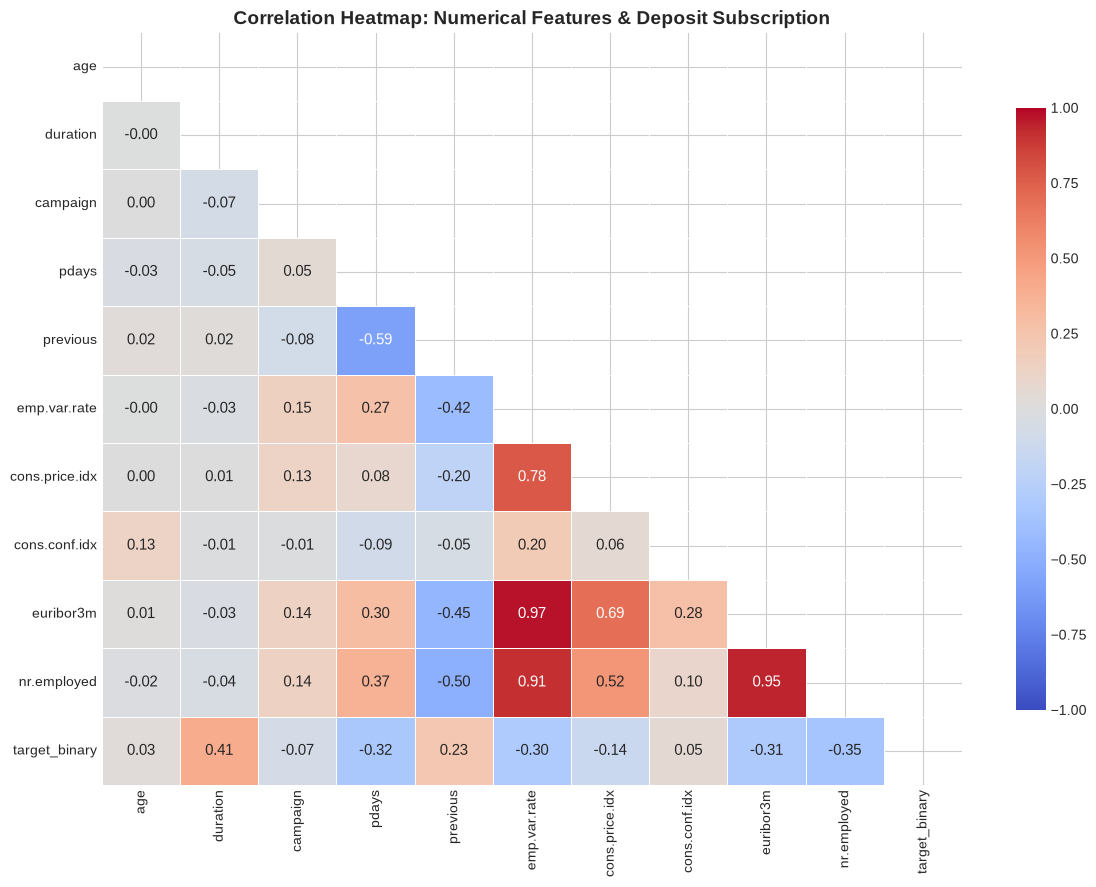

In [18]:
# Select numerical features + target binary
num_features = ['age', 'duration', 'campaign', 'pdays', 'previous', 
                'emp.var.rate', 'cons.price.idx', 'cons.conf.idx', 'euribor3m', 'nr.employed', 'target_binary']

corr_matrix = df[num_features].corr()

plt.figure(figsize=(12, 9))
mask = np.triu(np.ones_like(corr_matrix, dtype=bool))
sns.heatmap(corr_matrix, mask=mask, annot=True, fmt='.2f', cmap='coolwarm', 
            vmin=-1, vmax=1, linewidths=0.5, cbar_kws={'shrink': 0.8})
plt.title("Correlation Heatmap: Numerical Features & Deposit Subscription", fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

---
## 📈 8. Final Deliverables, Key Insights & Business Recommendations

### 8.1 Summary of Findings Across Analysis Dimensions
| Analysis Area | Core Finding | Strategic Implication |
| :--- | :--- | :--- |
| **Class Imbalance** | 88.7% Non-subscribers vs 11.3% Subscribers | Model evaluation must prioritize Precision-Recall AUC & F1 score over accuracy. |
| **Demographics** | Seniors (65+: 45.6%) and Students (<25: 31.4%) convert highest; Blue-collar converts lowest (6.9%). | Tailor specialized deposit products for retirees (wealth preservation) and students (savings starter). |
| **Channel** | Cellular outreach achieves 14.7% vs 5.2% for Telephone landlines. | Shift 100% of campaign resources to verified cellular contact lists. |
| **Outreach Fatigue** | Sharp drop after 1–3 calls; >6 calls yields only 3.7% conversion. | Institute strict hard cap: max 3 calls per client per campaign cycle. |
| **Call Duration** | Subscribers talk 3.4x longer (median 7.5 min vs 2.2 min for non-subscribers). | Reps should focus on active listening and objection handling early to keep prospects on the line. |
| **Macro Environment** | 23.9% conversion when Euribor < 1.5% vs 4.5% when Euribor > 4.5%. | Launch aggressive campaigns counter-cyclically when central bank rates dip. |

---

### 8.2 Prescriptive Recommendations for Bank Leadership
1. **Prioritize Targeted Customer Segments**:
   - Reallocate outbound telemarketing capacity away from cold mass calls toward pre-screened **retirees, students, and management professionals**.
2. **Eliminate Low-Yield Outreach Tactics**:
   - Cease outreach via fixed landline telephones; conversion is 65% lower than cellular.
   - Enforce an automatic CRM cutoff rule stopping contacts after **3 unanswered or uncommitted attempts**.
3. **Macro-Adaptive Campaign Scheduling**:
   - Time major marketing blitzes during periods of low interest rates (Euribor < 2.0%) or high customer liquidity (March, September, October).
4. **Machine Learning Pipeline Design Considerations**:
   - **Data Leakage Alert**: `duration` cannot be used as an input feature for real-time lead scoring prior to call dispatch because call duration is unknown before the call begins.
   - **Resampling & Cost-Sensitive Learning**: Given the 89:11 class imbalance, apply SMOTE or tune class weights ($w_{\\text{positive}} \\approx 8$) to optimize conversion recall.

---
### 🏁 Conclusion
Through systematic data inspection, thoughtful cleaning, feature engineering, and multi-dimensional visualization with **Pandas, Matplotlib, and Seaborn**, we transformed 41,188 raw survey records into actionable business intelligence.